Loading training dataset...
X_training shape: (100, 3)
Y_training shape: (100, 200)

Training GPR Multi-Output Surrogate Model...
Training complete!


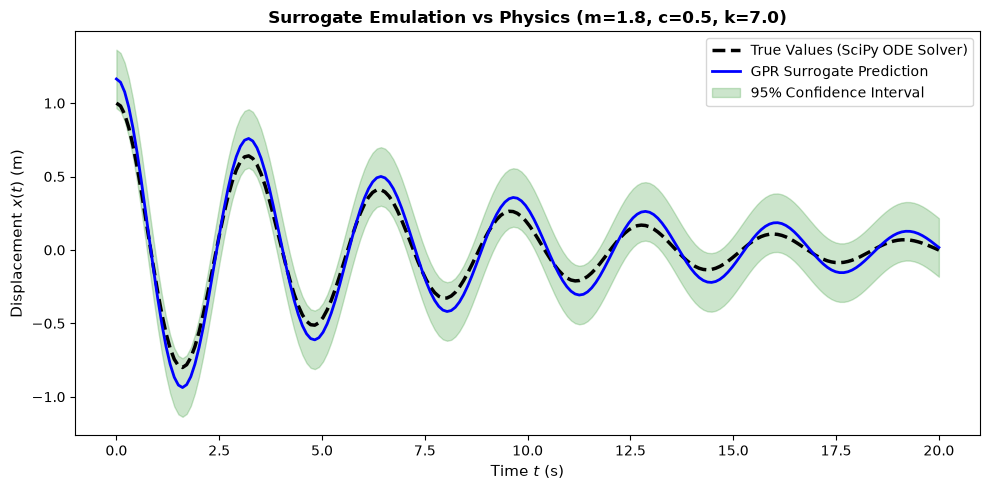

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# --- 1. Load Training Data ---
print("Loading training dataset...")
df_train = pd.read_csv('gpr_training_data.csv')

# Split DataFrame into Inputs (X) and Outputs (Y)
X_training = df_train[['mass', 'damping', 'spring']].values
Y_training = df_train.drop(columns=['mass', 'damping', 'spring']).values

print(f"X_training shape: {X_training.shape}")
print(f"Y_training shape: {Y_training.shape}")

# --- 2. Train GPR Model ---
kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2))
gpr = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=5, random_state=42)

print("\nTraining GPR Multi-Output Surrogate Model...")
gpr.fit(X_training, Y_training)
print("Training complete!")

# --- 3. Load True Test Data (For Comparison Plot) ---
df_true = pd.read_csv('oscillator_data.csv')
t_true = df_true['t'].values
true_trajectory = df_true['x'].values

# --- 4. Make Prediction ---
test_m, test_c, test_k = 1.8, 0.5, 7.0
X_test = np.array([[test_m, test_c, test_k]])
predicted_trajectory, y_std = gpr.predict(X_test, return_std=True)

# --- 5. Visualization ---
plt.figure(figsize=(10, 5))
plt.plot(t_true, true_trajectory, label='True Values (SciPy ODE Solver)', color='black', linewidth=2.5, linestyle='--')
plt.plot(t_true, predicted_trajectory[0], label='GPR Surrogate Prediction', color='blue', linewidth=2)

# 95% Confidence interval bounds from GPR standard deviation
upper_bound = predicted_trajectory[0] + 1.96 * y_std[0]
lower_bound = predicted_trajectory[0] - 1.96 * y_std[0]
plt.fill_between(t_true, lower_bound, upper_bound, color='green', alpha=0.2, label='95% Confidence Interval')

plt.title(f'Surrogate Emulation vs Physics (m={test_m}, c={test_c}, k={test_k})', fontsize=12, fontweight='bold')
plt.xlabel('Time $t$ (s)', fontsize=11)
plt.ylabel('Displacement $x(t)$ (m)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()